# Identifying Potentially Undervalued MLB Hitters: 2026 Offensive Performance Analysis

## Executive Summary

### Project Objective

This project evaluates MLB hitters whose actual offensive production may have fallen below their expected performance in 2026. Using Statcast-derived metrics and historical performance data from 2024–2026, the analysis identifies players who may have greater offensive potential than their current results suggest.

The primary objective is to distinguish hitters experiencing potentially unfavorable outcomes from those showing meaningful changes in their underlying offensive performance.

### Methodology

The analysis uses Python, pandas, and Matplotlib to evaluate offensive production through several metrics:

- **wOBA:** Measures overall offensive production by assigning different values to offensive outcomes.
- **xwOBA:** Estimates offensive performance based on underlying contact characteristics and strikeout/walk outcomes.
- **xwOBA Gap:** Calculated as xwOBA minus wOBA. A positive difference indicates expected production exceeded actual production.
- **Barrel Rate:** Measures the percentage of batted balls classified as barrels.
- **Hard-Hit Rate:** Measures the percentage of batted balls hit at 95 mph or greater.
- **Strikeout and Walk Rates:** Provide additional context about plate discipline and offensive approach.

Historical data from 2024–2026 was used to evaluate changes in production, contact quality, and consistency. A custom scoring framework helped narrow the candidate pool to five hitters for further evaluation.

### Key Findings

| Player | 2026 wOBA | 2026 xwOBA | Gap | Assessment |
|---|---:|---:|---:|---|
| Brandon Nimmo | .320 | .338 | +.018 | Strong expected-performance gap |
| Heliot Ramos | .312 | .329 | +.017 | Improving contact quality |
| Masyn Winn | .283 | .297 | +.014 | Moderate rebound indicators |
| Shea Langeliers | .347 | .352 | +.005 | Limited expected-performance gap |
| William Contreras | .330 | .334 | +.004 | Limited expected-performance gap |

**Heliot Ramos** emerged as a particularly compelling candidate because his barrel rate increased from 8.8% in 2025 to 13.8% in 2026, while his hard-hit rate improved from 47.4% to 48.4%. His positive xwOBA gap suggests that his actual offensive production did not fully reflect his underlying expected results.

**Brandon Nimmo** recorded the largest positive xwOBA gap among the five finalists. His contact-quality metrics remained relatively stable, suggesting that the gap between expected and actual production deserves further investigation.

**Masyn Winn** demonstrated a moderate positive expected-performance gap, although his declining barrel rate suggests a more cautious outlook.

### Baseball Operations Applications

This analysis provides a preliminary framework for identifying hitters who may warrant additional scouting or analytical evaluation. Potential applications include:

- Supporting player acquisition and roster evaluation.
- Identifying candidates for further offensive development analysis.
- Comparing actual production against expected offensive outcomes.
- Prioritizing hitters for video review and more detailed statistical modeling.

### Limitations

A positive xwOBA gap does not guarantee future improvement. Expected statistics do not fully account for every factor influencing offensive production, including defensive positioning, spray direction, baserunning, and changes in player health or approach.

Additionally, this analysis identifies statistical candidates rather than establishing whether players are financially undervalued. Contract value, acquisition cost, defensive contributions, and positional context would be necessary for a complete valuation.

### Conclusion

The analysis identifies five hitters whose offensive profiles warrant further investigation, with Heliot Ramos and Brandon Nimmo presenting particularly interesting cases for different reasons.

Combining expected offensive statistics with historical contact-quality trends provides a more informative starting point for player evaluation than relying exclusively on traditional production metrics.

In [101]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Success! Python libraries are working.")
print("Pandas version:", pd.__version__)


Success! Python libraries are working.
Pandas version: 3.1.1


In [102]:
# Load 2026 MLB Statcast data
import pandas as pd

df = pd.read_csv("stats.csv")

# Check the dataset
print("Number of rows and columns:", df.shape)

# Show the first 5 players
display(df.head())

# Show all column names
print("\nColumn names:")
print(df.columns.tolist())


Number of rows and columns: (267, 10)


,"last_name, first_name",player_id,year,pa,k_percent,bb_percent,woba,xwoba,barrel_batted_rate,hard_hit_percent
0,"Perez, Salvador",521692,2026,627,19.0,4.0,0.285,0.316,10.7,42.7
1,"Karros, Kyle",691720,2026,475,21.1,11.4,0.336,0.334,8.3,41.1
2,"Holliday, Jackson",702616,2026,354,23.7,9.6,0.284,0.293,6.4,33.1
3,"Contreras, William",661388,2026,640,14.7,9.5,0.330,0.334,8.5,44.1
4,"Heim, Jonah",641680,2026,390,17.9,6.9,0.275,0.285,5.9,32.3



Column names:
['last_name, first_name', 'player_id', 'year', 'pa', 'k_percent', 'bb_percent', 'woba', 'xwoba', 'barrel_batted_rate', 'hard_hit_percent']


In [103]:

# Calculate the gap between expected and actual wOBA
df["woba_gap"] = df["xwoba"] - df["woba"]

# Keep hitters with at least 300 plate appearances
qualified = df[df["pa"] >= 300].copy()

# Sort by largest positive wOBA gap
ranked = qualified.sort_values(
    by="woba_gap",
    ascending=False
)

# Display the top 10 hitters
top10 = ranked.head(10)

display(
    top10[
        [
            "last_name, first_name",
            "pa",
            "woba",
            "xwoba",
            "woba_gap"
        ]
    ]
)


,"last_name, first_name",pa,woba,xwoba,woba_gap
81,"Realmuto, J.T.",467,0.275,0.317,0.042
152,"Bailey, Patrick",345,0.271,0.307,0.036
139,"Witt Jr., Bobby",632,0.345,0.378,0.033
0,"Perez, Salvador",627,0.285,0.316,0.031
50,"Seager, Corey",436,0.320,0.350,0.030
223,"Wetherholt, JJ",619,0.318,0.347,0.029
224,"Montgomery, Braden",365,0.298,0.325,0.027
65,"Trout, Mike",634,0.354,0.381,0.027
147,"Merrill, Jackson",664,0.320,0.347,0.027
11,"Duran, Jarren",608,0.274,0.301,0.027


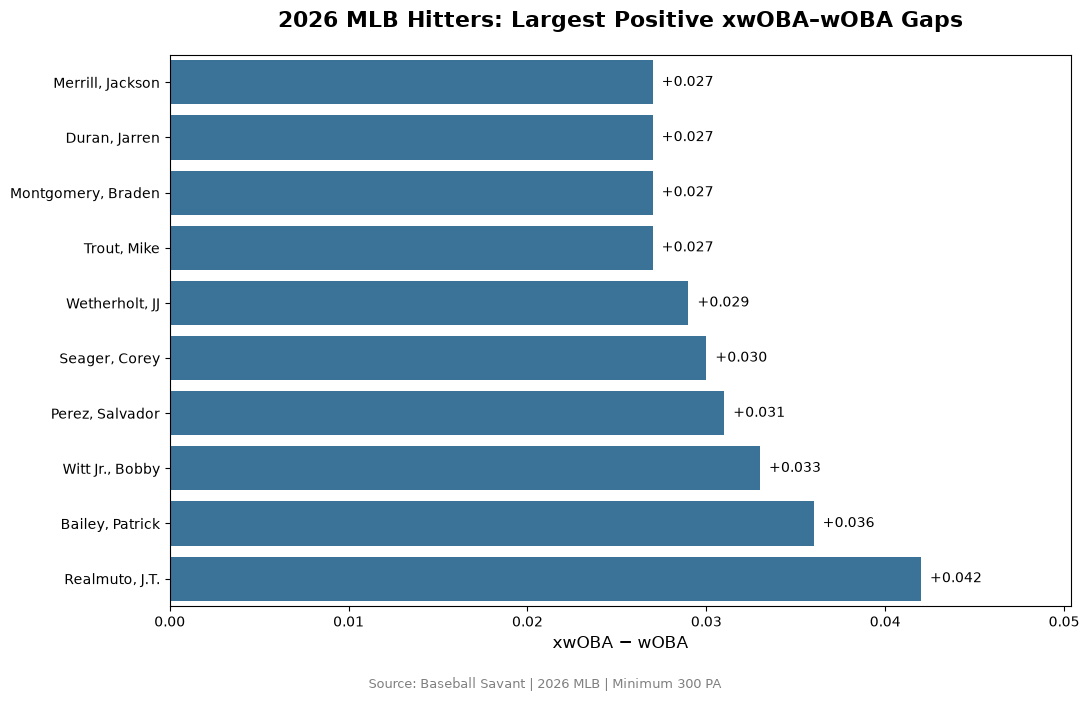

In [104]:

# Visualization 1: Top 10 positive wOBA gaps

import matplotlib.pyplot as plt
import seaborn as sns

# Sort players for a horizontal bar chart
chart_data = top10.sort_values("woba_gap")

plt.figure(figsize=(11, 7))

sns.barplot(
    data=chart_data,
    x="woba_gap",
    y="last_name, first_name",
    color="#2C75A7"
)

plt.title(
    "2026 MLB Hitters: Largest Positive xwOBA–wOBA Gaps",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("xwOBA − wOBA", fontsize=12)
plt.ylabel("")

# Display the gap at the end of each bar
for i, gap in enumerate(chart_data["woba_gap"]):
    plt.text(
        gap + 0.0005,
        i,
        f"+{gap:.3f}",
        va="center",
        fontsize=10
    )

plt.xlim(0, chart_data["woba_gap"].max() * 1.20)

plt.figtext(
    0.5, 0.01,
    "Source: Baseball Savant | 2026 MLB | Minimum 300 PA",
    ha="center",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# Save a high-resolution image for LinkedIn
plt.savefig(
    "2026_top10_woba_gaps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [105]:

# Examine contact quality for our top 10 hitters

# Check the exact column names
print(df.columns.tolist())


['last_name, first_name', 'player_id', 'year', 'pa', 'k_percent', 'bb_percent', 'woba', 'xwoba', 'barrel_batted_rate', 'hard_hit_percent', 'woba_gap']


In [106]:

# Display each column name separately
for column in df.columns:
    print(column)


last_name, first_name
player_id
year
pa
k_percent
bb_percent
woba
xwoba
barrel_batted_rate
hard_hit_percent
woba_gap


In [107]:

# Compare contact quality for our top 10 hitters

contact_quality = top10[
    [
        "last_name, first_name",
        "pa",
        "woba_gap",
        "barrel_batted_rate",
        "hard_hit_percent"
    ]
].copy()

# Rename columns for readability
contact_quality = contact_quality.rename(columns={
    "last_name, first_name": "Player",
    "pa": "PA",
    "woba_gap": "xwOBA Gap",
    "barrel_batted_rate": "Barrel %",
    "hard_hit_percent": "Hard-Hit %"
})

display(contact_quality.round(3))


,Player,PA,xwOBA Gap,Barrel %,Hard-Hit %
81,"Realmuto, J.T.",467,0.042,5.7,40.0
152,"Bailey, Patrick",345,0.036,7.7,42.4
139,"Witt Jr., Bobby",632,0.033,11.4,50.3
0,"Perez, Salvador",627,0.031,10.7,42.7
50,"Seager, Corey",436,0.030,14.8,48.9
223,"Wetherholt, JJ",619,0.029,7.4,44.9
224,"Montgomery, Braden",365,0.027,4.4,40.9
65,"Trout, Mike",634,0.027,16.0,46.3
147,"Merrill, Jackson",664,0.027,12.4,48.7
11,"Duran, Jarren",608,0.027,9.1,39.9


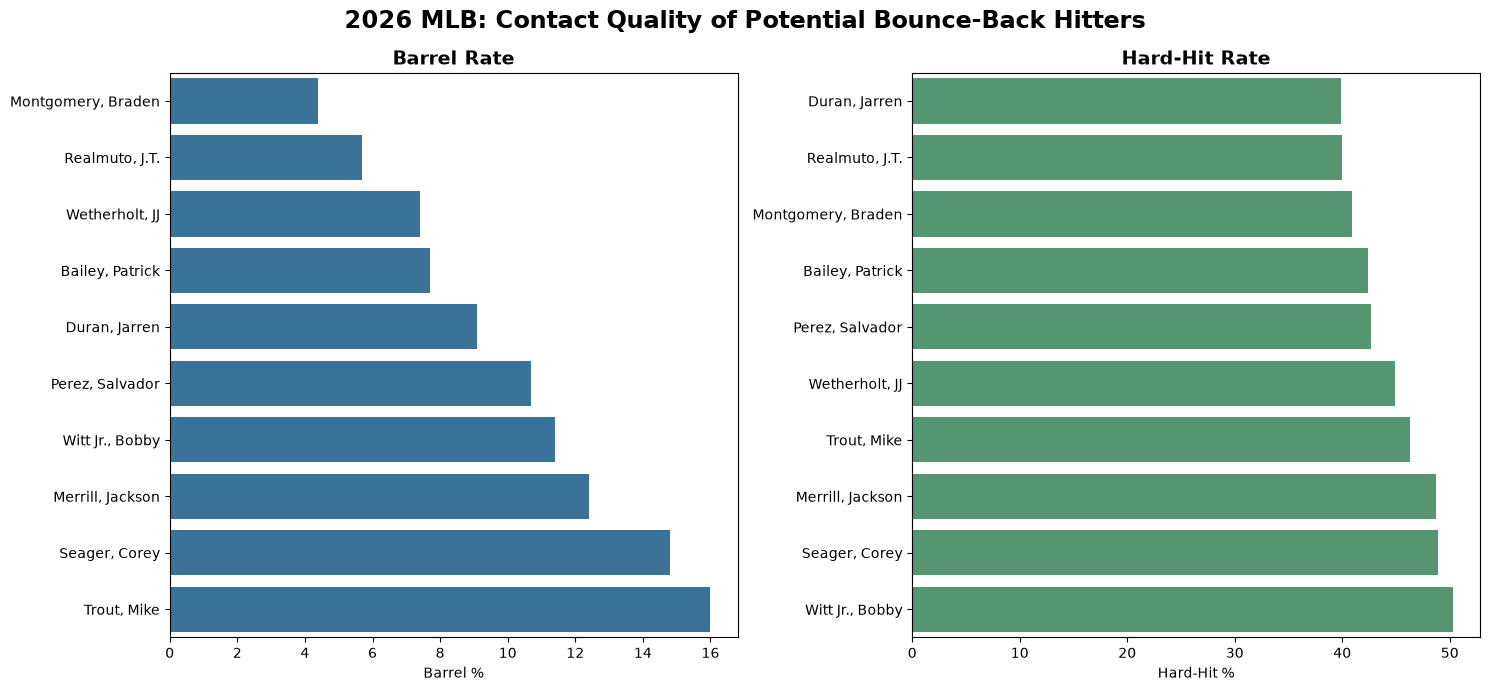

In [108]:

# Visualization 2: Contact quality comparison

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Sort by barrel rate
barrel_data = contact_quality.sort_values("Barrel %")

sns.barplot(
    data=barrel_data,
    x="Barrel %",
    y="Player",
    color="#2C75A7",
    ax=axes[0]
)

axes[0].set_title("Barrel Rate", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Barrel %")
axes[0].set_ylabel("")

# Sort by hard-hit rate
hard_hit_data = contact_quality.sort_values("Hard-Hit %")

sns.barplot(
    data=hard_hit_data,
    x="Hard-Hit %",
    y="Player",
    color="#4C9F70",
    ax=axes[1]
)

axes[1].set_title("Hard-Hit Rate", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Hard-Hit %")
axes[1].set_ylabel("")

fig.suptitle(
    "2026 MLB: Contact Quality of Potential Bounce-Back Hitters",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "2026_contact_quality_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [109]:

# Compare our top 10 hitters against the full 2026 sample

metrics = ["barrel_batted_rate", "hard_hit_percent"]

# Calculate full-sample averages
league_comparison = qualified[metrics].mean()

print("2026 qualified hitter sample averages:")
print(league_comparison.round(2))

# Calculate each top-10 hitter's percentile rank
for metric in metrics:
    top10[metric + "_percentile"] = top10[metric].apply(
        lambda x: (qualified[metric] <= x).mean() * 100
    )

# Display the results
display(
    top10[
        [
            "last_name, first_name",
            "woba_gap",
            "barrel_batted_rate_percentile",
            "hard_hit_percent_percentile"
        ]
    ].round(1)
)


2026 qualified hitter sample averages:
barrel_batted_rate     8.17
hard_hit_percent      39.74
dtype: float64


,"last_name, first_name",woba_gap,barrel_batted_rate_percentile,hard_hit_percent_percentile
81,"Realmuto, J.T.",0.0,29.6,47.2
152,"Bailey, Patrick",0.0,50.6,61.8
139,"Witt Jr., Bobby",0.0,76.4,92.9
0,"Perez, Salvador",0.0,72.3,63.3
50,"Seager, Corey",0.0,95.1,89.5
223,"Wetherholt, JJ",0.0,46.8,77.2
224,"Montgomery, Braden",0.0,20.6,51.3
65,"Trout, Mike",0.0,97.8,82.4
147,"Merrill, Jackson",0.0,83.9,89.1
11,"Duran, Jarren",0.0,61.4,46.4


In [110]:

# Display accurate wOBA gaps and percentile rankings

results = top10[
    [
        "last_name, first_name",
        "woba_gap",
        "barrel_batted_rate_percentile",
        "hard_hit_percent_percentile"
    ]
].copy()

results = results.rename(columns={
    "last_name, first_name": "Player",
    "woba_gap": "xwOBA Gap",
    "barrel_batted_rate_percentile": "Barrel Percentile",
    "hard_hit_percent_percentile": "Hard-Hit Percentile"
})

display(
    results.style.format({
        "xwOBA Gap": "{:+.3f}",
        "Barrel Percentile": "{:.1f}",
        "Hard-Hit Percentile": "{:.1f}"
    })
)


,Player,xwOBA Gap,Barrel Percentile,Hard-Hit Percentile
81,"Realmuto, J.T.",+0.042,29.6,47.2
152,"Bailey, Patrick",+0.036,50.6,61.8
139,"Witt Jr., Bobby",+0.033,76.4,92.9
0,"Perez, Salvador",+0.031,72.3,63.3
50,"Seager, Corey",+0.030,95.1,89.5
223,"Wetherholt, JJ",+0.029,46.8,77.2
224,"Montgomery, Braden",+0.027,20.6,51.3
65,"Trout, Mike",+0.027,97.8,82.4
147,"Merrill, Jackson",+0.027,83.9,89.1
11,"Duran, Jarren",+0.027,61.4,46.4


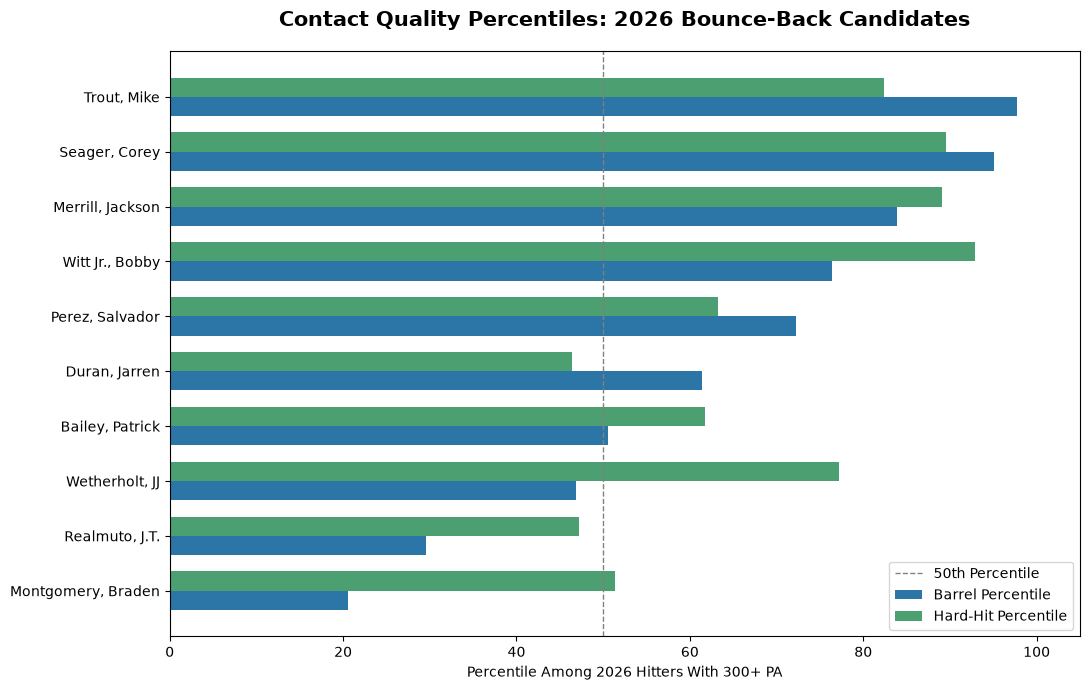

In [111]:

# Visualization 3: Contact quality percentile comparison

plot_data = results.sort_values("Barrel Percentile")

fig, ax = plt.subplots(figsize=(11, 7))

y = np.arange(len(plot_data))
bar_height = 0.35

ax.barh(
    y - bar_height / 2,
    plot_data["Barrel Percentile"],
    bar_height,
    label="Barrel Percentile",
    color="#2C75A7"
)

ax.barh(
    y + bar_height / 2,
    plot_data["Hard-Hit Percentile"],
    bar_height,
    label="Hard-Hit Percentile",
    color="#4C9F70"
)

ax.set_yticks(y)
ax.set_yticklabels(plot_data["Player"])
ax.set_xlim(0, 105)

ax.axvline(
    50,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="50th Percentile"
)

ax.set_xlabel("Percentile Among 2026 Hitters With 300+ PA")
ax.set_title(
    "Contact Quality Percentiles: 2026 Bounce-Back Candidates",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    "2026_contact_quality_percentiles.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [112]:

# Create an exploratory bounce-back candidate score

# Work with the full qualified hitter sample
scored = qualified.copy()

# Percentile ranks across all qualified hitters
scored["gap_percentile"] = (
    scored["woba_gap"].rank(pct=True) * 100
)

scored["barrel_percentile"] = (
    scored["barrel_batted_rate"].rank(pct=True) * 100
)

scored["hard_hit_percentile"] = (
    scored["hard_hit_percent"].rank(pct=True) * 100
)

# Weighted exploratory score
scored["bounce_back_score"] = (
    0.50 * scored["gap_percentile"]
    + 0.25 * scored["barrel_percentile"]
    + 0.25 * scored["hard_hit_percentile"]
)

# Restrict to hitters with a positive xwOBA gap
candidates = scored[scored["woba_gap"] > 0].copy()

# Rank highest-scoring candidates
candidates = candidates.sort_values(
    "bounce_back_score",
    ascending=False
)

display(
    candidates[
        [
            "last_name, first_name",
            "pa",
            "woba_gap",
            "bounce_back_score"
        ]
    ].head(15).round(3)
)


,"last_name, first_name",pa,woba_gap,bounce_back_score
50,"Seager, Corey",436,0.030,95.365
238,"Alonso, Pete",700,0.023,94.850
43,"Wood, James",623,0.020,94.101
65,"Trout, Mike",634,0.027,93.727
234,"Ohtani, Shohei",618,0.020,92.743
31,"Soto, Juan",482,0.026,92.416
139,"Witt Jr., Bobby",632,0.033,91.948
147,"Merrill, Jackson",664,0.027,91.479
186,"Tatis Jr., Fernando",704,0.021,91.199
119,"Alvarez, Yordan",691,0.013,87.594


In [113]:

# Identify hitters with potentially overlooked offensive production

# Calculate sample averages
avg_woba = qualified["woba"].mean()
avg_xwoba = qualified["xwoba"].mean()

print(f"Sample average wOBA: {avg_woba:.3f}")
print(f"Sample average xwOBA: {avg_xwoba:.3f}")

# Find hitters whose actual production is below average
# but whose expected production is above average
overlooked = scored[
    (scored["woba"] < avg_woba) &
    (scored["xwoba"] > avg_xwoba) &
    (scored["woba_gap"] > 0)
].copy()

# Rank by our existing exploratory score
overlooked = overlooked.sort_values(
    "bounce_back_score",
    ascending=False
)

print(f"\nPotential overlooked hitters: {len(overlooked)}")

display(
    overlooked[
        [
            "last_name, first_name",
            "pa",
            "woba",
            "xwoba",
            "woba_gap",
            "bounce_back_score"
        ]
    ].head(15).round(3)
)


Sample average wOBA: 0.324
Sample average xwOBA: 0.321

Potential overlooked hitters: 33


,"last_name, first_name",pa,woba,xwoba,woba_gap,bounce_back_score
50,"Seager, Corey",436,0.320,0.350,0.030,95.365
147,"Merrill, Jackson",664,0.320,0.347,0.027,91.479
245,"Ramos, Heliot",442,0.312,0.329,0.017,86.423
113,"Nootbaar, Lars",334,0.320,0.343,0.023,86.236
24,"Grisham, Trent",484,0.311,0.337,0.026,84.036
158,"Alvarez, Francisco",420,0.313,0.322,0.009,81.788
141,"House, Brady",355,0.313,0.333,0.020,81.414
101,"Nimmo, Brandon",655,0.320,0.338,0.018,80.431
223,"Wetherholt, JJ",619,0.318,0.347,0.029,79.916
71,"Marte, Ketel",624,0.323,0.349,0.026,79.682


In [114]:

# Create player evaluation profiles

target_players = [
    "Ramos, Heliot",
    "Nootbaar, Lars",
    "Grisham, Trent"
]

player_profiles = scored[
    scored["last_name, first_name"].isin(target_players)
].copy()

columns = [
    "last_name, first_name",
    "pa",
    "woba",
    "xwoba",
    "woba_gap",
    "k_percent",
    "bb_percent",
    "barrel_batted_rate",
    "hard_hit_percent",
    "bounce_back_score"
]

player_profiles = player_profiles[columns]

display(player_profiles.round(3))


,"last_name, first_name",pa,woba,xwoba,woba_gap,k_percent,bb_percent,barrel_batted_rate,hard_hit_percent,bounce_back_score
24,"Grisham, Trent",484,0.311,0.337,0.026,18.4,12.6,9.6,45.3,84.036
113,"Nootbaar, Lars",334,0.320,0.343,0.023,21.0,13.8,10.1,49.5,86.236
245,"Ramos, Heliot",442,0.312,0.329,0.017,27.4,7.0,13.8,48.4,86.423


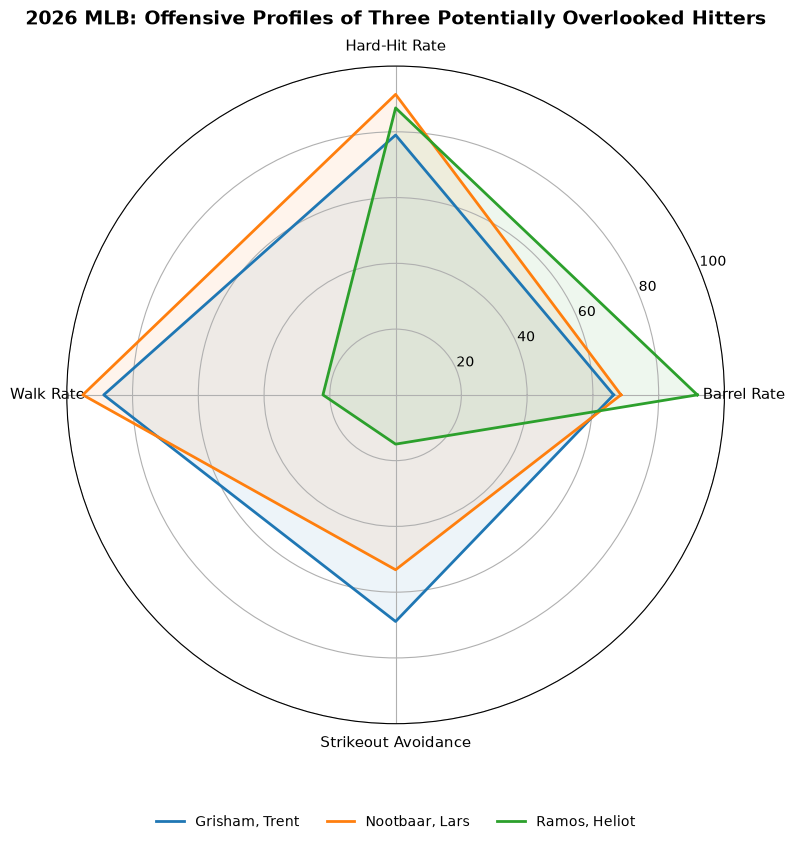

In [115]:

# Visualization 4: Player profile comparison

metrics = {
    "barrel_batted_rate": "Barrel Rate",
    "hard_hit_percent": "Hard-Hit Rate",
    "bb_percent": "Walk Rate",
    "k_percent": "Strikeout Avoidance"
}

# Calculate sample percentile ranks
profile_scores = scored[
    scored["last_name, first_name"].isin(target_players)
].copy()

for metric in metrics:
    profile_scores[metric + "_pct"] = (
        profile_scores[metric].apply(
            lambda x: (
                (qualified[metric] <= x).mean() * 100
                if metric != "k_percent"
                else (qualified[metric] >= x).mean() * 100
            )
        )
    )

# Prepare radar chart
categories = list(metrics.values())
angles = np.linspace(
    0, 2 * np.pi, len(categories), endpoint=False
).tolist()
angles += angles[:1]

fig, ax = plt.subplots(
    figsize=(9, 9),
    subplot_kw={"polar": True}
)

for _, player in profile_scores.iterrows():
    values = [
        player[metric + "_pct"]
        for metric in metrics
    ]
    values += values[:1]

    ax.plot(
        angles,
        values,
        linewidth=2,
        label=player["last_name, first_name"]
    )
    ax.fill(angles, values, alpha=0.08)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11)
ax.set_ylim(0, 100)

ax.set_title(
    "2026 MLB: Offensive Profiles of Three Potentially Overlooked Hitters",
    fontsize=14,
    fontweight="bold",
    pad=30
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False,
    fontsize=10
)
plt.subplots_adjust(top=0.85, bottom=0.20)
plt.tight_layout(pad=3)
plt.savefig(
    "2026_player_profile_radar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [116]:

# Historical analysis: 2024–2026

import pandas as pd
import matplotlib.pyplot as plt

df_2024 = pd.read_csv("stats_2024.csv")
df_2025 = pd.read_csv("stats_2025.csv")

# Use the existing 2026 data
df_2026 = pd.read_csv("stats.csv")

# Check that the files have matching columns
for year, data in [(2024, df_2024),
                   (2025, df_2025),
                   (2026, df_2026)]:
    print(f"\n{year}: {len(data)} hitters")
    print(data.columns.tolist())



2024: 129 hitters
['last_name, first_name', 'player_id', 'year', 'pa', 'k_percent', 'bb_percent', 'woba', 'xwoba', 'sweet_spot_percent', 'barrel_batted_rate', 'hard_hit_percent', 'avg_best_speed', 'avg_hyper_speed', 'whiff_percent', 'swing_percent']

2025: 145 hitters
['last_name, first_name', 'player_id', 'year', 'pa', 'k_percent', 'bb_percent', 'woba', 'xwoba', 'sweet_spot_percent', 'barrel_batted_rate', 'hard_hit_percent', 'avg_best_speed', 'avg_hyper_speed', 'whiff_percent', 'swing_percent']

2026: 267 hitters
['last_name, first_name', 'player_id', 'year', 'pa', 'k_percent', 'bb_percent', 'woba', 'xwoba', 'barrel_batted_rate', 'hard_hit_percent']


In [117]:

# Combine 2024, 2025, and 2026 data

historical = pd.concat(
    [df_2024, df_2025, df_2026],
    ignore_index=True
)

# Calculate the difference between expected and actual wOBA
historical["woba_gap"] = (
    historical["xwoba"] - historical["woba"]
)

# Three hitters from our player profiles
players = [
    "Grisham, Trent",
    "Nootbaar, Lars",
    "Ramos, Heliot"
]

comparison = historical[
    historical["last_name, first_name"].isin(players)
].copy()

comparison = comparison.sort_values(
    ["last_name, first_name", "year"]
)

# Display the historical statistics
display(
    comparison[
        [
            "last_name, first_name",
            "year",
            "pa",
            "woba",
            "xwoba",
            "woba_gap",
            "barrel_batted_rate",
            "hard_hit_percent"
        ]
    ].round(3)
)


,"last_name, first_name",year,pa,woba,xwoba,woba_gap,barrel_batted_rate,hard_hit_percent
214,"Grisham, Trent",2025,581,0.353,0.370,0.017,14.2,46.4
298,"Grisham, Trent",2026,484,0.311,0.337,0.026,9.6,45.3
213,"Nootbaar, Lars",2025,583,0.304,0.317,0.013,10.2,50.0
387,"Nootbaar, Lars",2026,334,0.320,0.343,0.023,10.1,49.5
121,"Ramos, Heliot",2024,518,0.339,0.338,-0.001,14.7,47.5
165,"Ramos, Heliot",2025,695,0.319,0.320,0.001,8.8,47.4
519,"Ramos, Heliot",2026,442,0.312,0.329,0.017,13.8,48.4


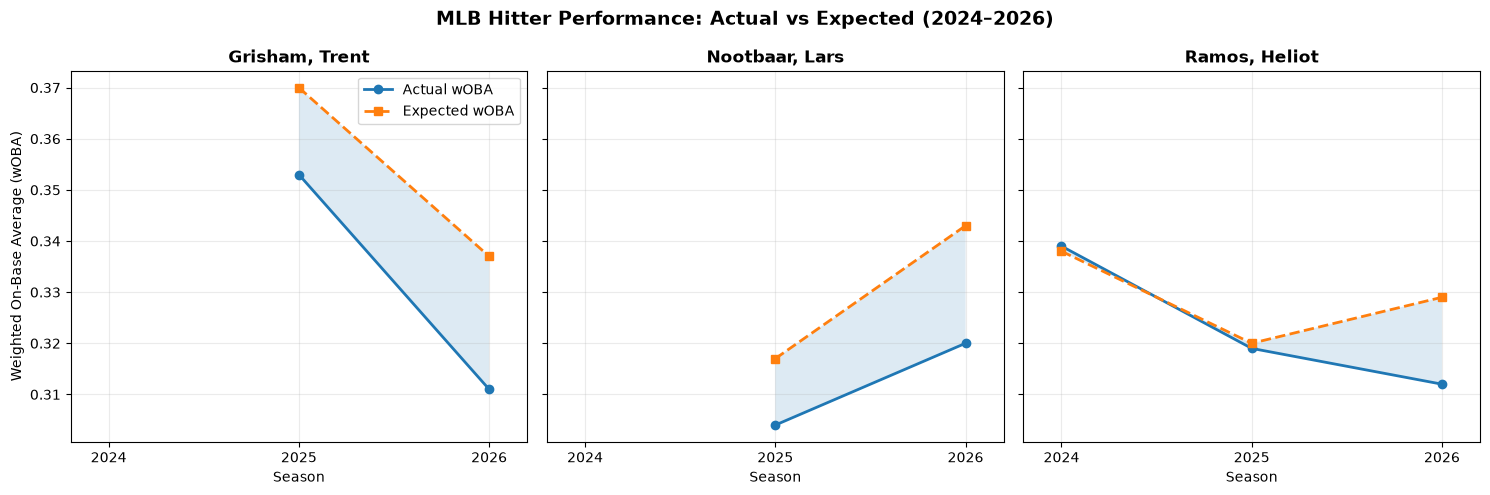

In [118]:

# Visualization 5: Historical wOBA vs xwOBA trends

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, player in zip(axes, players):

    subset = comparison[
        comparison["last_name, first_name"] == player
    ].sort_values("year")

    ax.plot(
        subset["year"],
        subset["woba"],
        marker="o",
        linewidth=2,
        label="Actual wOBA"
    )

    ax.plot(
        subset["year"],
        subset["xwoba"],
        marker="s",
        linewidth=2,
        linestyle="--",
        label="Expected wOBA"
    )

    ax.fill_between(
        subset["year"],
        subset["woba"],
        subset["xwoba"],
        alpha=0.15
    )

    ax.set_title(player, fontweight="bold")
    ax.set_xlabel("Season")
    ax.set_xticks([2024, 2025, 2026])
    ax.set_xlim(2023.8, 2026.2)
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Weighted On-Base Average (wOBA)")
axes[0].legend(loc="best")

fig.suptitle(
    "MLB Hitter Performance: Actual vs Expected (2024–2026)",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "2024_2026_hitter_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [119]:

# Create a refined 2026 bounce-back ranking

ranking = df_2026.copy()

# Calculate expected minus actual production
ranking["woba_gap"] = (
    ranking["xwoba"] - ranking["woba"]
)

# Rank each metric within the 2026 sample
ranking["gap_pct"] = (
    ranking["woba_gap"].rank(pct=True) * 100
)

ranking["barrel_pct"] = (
    ranking["barrel_batted_rate"].rank(pct=True) * 100
)

ranking["hard_hit_pct"] = (
    ranking["hard_hit_percent"].rank(pct=True) * 100
)

ranking["walk_pct"] = (
    ranking["bb_percent"].rank(pct=True) * 100
)

ranking["contact_pct"] = (
    (1 - ranking["k_percent"].rank(pct=True)) * 100
)

# Weighted exploratory score
ranking["refined_score"] = (
    0.35 * ranking["gap_pct"] +
    0.25 * ranking["barrel_pct"] +
    0.20 * ranking["hard_hit_pct"] +
    0.10 * ranking["walk_pct"] +
    0.10 * ranking["contact_pct"]
)

# Focus on hitters with positive gaps
# and at least 300 plate appearances
candidates = ranking[
    (ranking["woba_gap"] > 0) &
    (ranking["pa"] >= 300)
].copy()

top_candidates = candidates.nlargest(
    15, "refined_score"
)

display(
    top_candidates[
        [
            "last_name, first_name",
            "pa",
            "woba",
            "xwoba",
            "woba_gap",
            "barrel_batted_rate",
            "hard_hit_percent",
            "k_percent",
            "bb_percent",
            "refined_score"
        ]
    ].round(3)
)


,"last_name, first_name",pa,woba,xwoba,woba_gap,barrel_batted_rate,hard_hit_percent,k_percent,bb_percent,refined_score
31,"Soto, Juan",482,0.385,0.411,0.026,14.0,48.1,13.5,16.2,92.584
119,"Alvarez, Yordan",691,0.429,0.442,0.013,16.0,53.8,17.2,15.8,88.221
238,"Alonso, Pete",700,0.379,0.402,0.023,15.3,56.2,24.1,11.6,87.612
65,"Trout, Mike",634,0.354,0.381,0.027,16.0,46.3,26.0,16.9,87.022
139,"Witt Jr., Bobby",632,0.345,0.378,0.033,11.4,50.3,17.2,10.6,87.004
43,"Wood, James",623,0.383,0.403,0.020,18.6,58.9,28.7,16.4,86.798
234,"Ohtani, Shohei",618,0.377,0.397,0.020,16.4,52.1,24.6,13.1,86.713
50,"Seager, Corey",436,0.320,0.350,0.030,14.8,48.9,23.6,10.3,86.376
186,"Tatis Jr., Fernando",704,0.358,0.379,0.021,12.7,53.9,18.5,9.1,84.429
113,"Nootbaar, Lars",334,0.320,0.343,0.023,10.1,49.5,21.0,13.8,82.547


In [120]:

# Identify potentially overlooked offensive performers

# Use the full qualified 2026 sample
avg_woba = ranking["woba"].mean()
avg_xwoba = ranking["xwoba"].mean()

print(f"Sample average wOBA: {avg_woba:.3f}")
print(f"Sample average xwOBA: {avg_xwoba:.3f}")

overlooked = ranking[
    (ranking["pa"] >= 300) &
    (ranking["woba"] < avg_woba) &
    (ranking["xwoba"] > avg_xwoba) &
    (ranking["woba_gap"] > 0)
].copy()

overlooked = overlooked.sort_values(
    "refined_score", ascending=False
)

print(f"\nPotential overlooked hitters: {len(overlooked)}")

display(
    overlooked[
        [
            "last_name, first_name",
            "pa",
            "woba",
            "xwoba",
            "woba_gap",
            "barrel_batted_rate",
            "hard_hit_percent",
            "refined_score"
        ]
    ].head(20).round(3)
)


Sample average wOBA: 0.324
Sample average xwOBA: 0.321

Potential overlooked hitters: 33


,"last_name, first_name",pa,woba,xwoba,woba_gap,barrel_batted_rate,hard_hit_percent,refined_score
50,"Seager, Corey",436,0.320,0.350,0.030,14.8,48.9,86.376
113,"Nootbaar, Lars",334,0.320,0.343,0.023,10.1,49.5,82.547
24,"Grisham, Trent",484,0.311,0.337,0.026,9.6,45.3,81.330
147,"Merrill, Jackson",664,0.320,0.347,0.027,12.4,48.7,77.406
223,"Wetherholt, JJ",619,0.318,0.347,0.029,7.4,44.9,75.487
71,"Marte, Ketel",624,0.323,0.349,0.026,9.4,43.0,74.934
236,"Machado, Manny",677,0.310,0.328,0.018,9.7,43.6,73.258
245,"Ramos, Heliot",442,0.312,0.329,0.017,13.8,48.4,73.174
176,"Guerrero Jr., Vladimir",609,0.305,0.331,0.026,6.9,44.3,73.006
158,"Alvarez, Francisco",420,0.313,0.322,0.009,15.4,48.0,72.528


In [123]:


# Historical comparison of leading overlooked candidates

top_candidate_names = overlooked.head(10)["last_name, first_name"].tolist()

historical_candidates = historical[
    historical["last_name, first_name"].isin(top_candidate_names)
].copy()

historical_candidates = historical_candidates.sort_values(
    ["last_name, first_name", "year"]
)

display(
    historical_candidates[
        [
            "last_name, first_name",
            "year",
            "pa",
            "woba",
            "xwoba",
            "woba_gap",
            "barrel_batted_rate",
            "hard_hit_percent"
        ]
    ].round(3)
)



,"last_name, first_name",year,pa,woba,xwoba,woba_gap,barrel_batted_rate,hard_hit_percent
432,"Alvarez, Francisco",2026,420,0.313,0.322,0.009,15.4,48.0
214,"Grisham, Trent",2025,581,0.353,0.370,0.017,14.2,46.4
298,"Grisham, Trent",2026,484,0.311,0.337,0.026,9.6,45.3
107,"Guerrero Jr., Vladimir",2024,697,0.398,0.413,0.015,13.8,54.9
271,"Guerrero Jr., Vladimir",2025,680,0.366,0.384,0.018,12.2,50.7
450,"Guerrero Jr., Vladimir",2026,609,0.305,0.331,0.026,6.9,44.3
104,"Machado, Manny",2024,643,0.340,0.340,0.000,11.0,48.8
262,"Machado, Manny",2025,678,0.341,0.354,0.013,12.9,51.5
510,"Machado, Manny",2026,677,0.310,0.328,0.018,9.7,43.6
42,"Marte, Ketel",2024,583,0.391,0.394,0.003,12.3,53.8


In [122]:

# Compare 2025 and 2026 performance for returning hitters

metrics = [
    "woba",
    "xwoba",
    "barrel_batted_rate",
    "hard_hit_percent"
]

previous = df_2025.set_index("player_id")[metrics]
current = df_2026.set_index("player_id")[metrics]

changes = current.join(
    previous,
    how="inner",
    lsuffix="_2026",
    rsuffix="_2025"
)

for metric in metrics:
    changes[f"{metric}_change"] = (
        changes[f"{metric}_2026"] -
        changes[f"{metric}_2025"]
    )

# Attach player names and 2026 plate appearances
changes = changes.join(
    df_2026.set_index("player_id")[
        ["last_name, first_name", "pa", "woba_gap"]
    ]
)

# Find hitters whose actual production declined
# but whose expected production declined less
bounceback_trends = changes[
    (changes["woba_change"] < 0) &
    (changes["woba_gap"] > 0)
].copy()

bounceback_trends = bounceback_trends.sort_values(
    "woba_gap", ascending=False
)

display(
    bounceback_trends[
        [
            "last_name, first_name",
            "pa",
            "woba_change",
            "xwoba_change",
            "barrel_batted_rate_change",
            "hard_hit_percent_change",
            "woba_gap"
        ]
    ].head(20).round(3)
)

print("Returning hitters:", len(changes))
print("Potential bounce-back candidates:", len(bounceback_trends))


/var/folders/7w/nxlm7tl15j12lysld6rwq_lw0000gn/T/ipykernel_71239/852976021.py:13: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  changes = current.join(


KeyError: "['woba_gap'] not in index"

In [ ]:
df_2026["woba_gap"] = df_2026["xwoba"] - df_2026["woba"]

In [ ]:

# Classify bounce-back candidates by underlying trends

bounceback_trends = bounceback_trends.copy()

bounceback_trends["signal"] = "Mixed"

bounceback_trends.loc[
    bounceback_trends["xwoba_change"] >= 0,
    "signal"
] = "Strong"

# Display strongest candidates first
strong_candidates = bounceback_trends[
    bounceback_trends["signal"] == "Strong"
].sort_values("woba_gap", ascending=False)

print("Strong rebound signals:", len(strong_candidates))
print("Mixed rebound signals:",
      (bounceback_trends["signal"] == "Mixed").sum())

display(
    strong_candidates[
        [
            "last_name, first_name",
            "pa",
            "woba_change",
            "xwoba_change",
            "barrel_batted_rate_change",
            "hard_hit_percent_change",
            "woba_gap"
        ]
    ].round(3)
)


Strong rebound signals: 13
Mixed rebound signals: 29


,"last_name, first_name",pa,woba_change,xwoba_change,barrel_batted_rate_change,hard_hit_percent_change,woba_gap
player_id,,,,,,,
592663,"Realmuto, J.T.",467,-0.032,0.001,-3.1,-5.5,0.042
677951,"Witt Jr., Bobby",632,-0.015,0.013,-1.1,1.8,0.033
663538,"Hoerner, Nico",689,-0.027,0.000,-1.0,-1.2,0.025
621493,"Ward, Taylor",607,-0.027,0.001,-8.6,-4.4,0.022
680574,"McLain, Matt",496,-0.014,0.002,1.2,-5.1,0.021
607043,"Nimmo, Brandon",655,-0.009,0.017,0.1,0.2,0.018
664761,"Bohm, Alec",629,-0.013,0.003,-0.2,-2.6,0.018
671218,"Ramos, Heliot",442,-0.007,0.009,5.0,1.0,0.017
518692,"Freeman, Freddie",657,-0.022,0.013,-2.3,-4.4,0.015


In [ ]:

# Select five players for detailed scouting reports

# Begin with the 13 strong rebound candidates
final_pool = strong_candidates.copy()

# Rank players by three indicators
final_pool["gap_rank"] = final_pool["woba_gap"].rank(
    ascending=False, pct=True
)

final_pool["expected_trend_rank"] = final_pool["xwoba_change"].rank(
    ascending=True, pct=True
)

final_pool["barrel_trend_rank"] = final_pool[
    "barrel_batted_rate_change"
].rank(ascending=True, pct=True)

# Exploratory composite score (0-100)
final_pool["portfolio_score"] = 100 * (
    0.40 * final_pool["gap_rank"] +
    0.35 * final_pool["expected_trend_rank"] +
    0.25 * final_pool["barrel_trend_rank"]
)

final_pool = final_pool.sort_values(
    "portfolio_score", ascending=False
)

final_five = final_pool.head(5).copy()

display(
    final_five[
        [
            "last_name, first_name",
            "pa",
            "woba_change",
            "xwoba_change",
            "barrel_batted_rate_change",
            "hard_hit_percent_change",
            "woba_gap",
            "portfolio_score"
        ]
    ].round(3)
)


,"last_name, first_name",pa,woba_change,xwoba_change,barrel_batted_rate_change,hard_hit_percent_change,woba_gap,portfolio_score
player_id,,,,,,,,
669127,"Langeliers, Shea",467,-0.018,0.023,2.0,-1.9,0.005,93.077
661388,"Contreras, William",640,-0.002,0.006,2.1,-4.4,0.004,81.923
671218,"Ramos, Heliot",442,-0.007,0.009,5.0,1.0,0.017,71.154
607043,"Nimmo, Brandon",655,-0.009,0.017,0.1,0.2,0.018,69.615
691026,"Winn, Masyn",532,-0.014,0.011,-1.5,0.3,0.014,62.692


In [ ]:

# Export historical profiles for all five finalists

# Use the five players selected in your final ranking
player_ids = [669127, 661388, 671218, 607043, 691026]

# Rebuild the historical dataset directly from the original CSVs
historical = pd.concat(
    [df_2024, df_2025, df_2026],
    ignore_index=True
)

# Ensure player IDs have consistent numeric types
historical["player_id"] = pd.to_numeric(
    historical["player_id"], errors="coerce"
)

# Select the five finalists
final_profiles = historical[
    historical["player_id"].isin(player_ids)
].copy()

# Calculate xwOBA - wOBA
final_profiles["woba_gap"] = (
    final_profiles["xwoba"] - final_profiles["woba"]
)

# Sort by player and year
final_profiles = final_profiles.sort_values(
    ["last_name, first_name", "year"]
)

# Export
final_profiles.to_csv(
    "2026_final_five_player_profiles.csv",
    index=False
)

# Verify
print("Players exported:", final_profiles["player_id"].nunique())
print("Total season records:", len(final_profiles))

display(
    final_profiles[
        [
            "last_name, first_name",
            "year",
            "pa",
            "woba",
            "xwoba",
            "woba_gap",
            "barrel_batted_rate",
            "hard_hit_percent"
        ]
    ].round(3)
)


Players exported: 5
Total season records: 15


,"last_name, first_name",year,pa,woba,xwoba,woba_gap,barrel_batted_rate,hard_hit_percent
108,"Contreras, William",2024,679,0.359,0.356,-0.003,10.0,49.5
203,"Contreras, William",2025,659,0.332,0.328,-0.004,6.4,48.5
277,"Contreras, William",2026,640,0.330,0.334,0.004,8.5,44.1
1,"Langeliers, Shea",2024,534,0.315,0.328,0.013,12.8,44.0
153,"Langeliers, Shea",2025,522,0.365,0.329,-0.036,11.3,44.9
397,"Langeliers, Shea",2026,467,0.347,0.352,0.005,13.3,43.0
112,"Nimmo, Brandon",2024,663,0.321,0.338,0.017,9.2,47.4
228,"Nimmo, Brandon",2025,652,0.329,0.321,-0.008,8.8,50.2
375,"Nimmo, Brandon",2026,655,0.320,0.338,0.018,8.9,50.4
121,"Ramos, Heliot",2024,518,0.339,0.338,-0.001,14.7,47.5


In [ ]:

# Generate scouting summaries for all five finalists

for player_id, data in final_profiles.groupby("player_id"):
    data = data.sort_values("year")

    name = data["last_name, first_name"].iloc[0]
    current = data[data["year"] == 2026]

    if current.empty:
        continue

    current = current.iloc[0]

    print("=" * 55)
    print(f"PLAYER EVALUATION: {name}")
    print("=" * 55)

    print("\nHistorical performance:")
    display(
        data[
            [
                "year", "pa", "woba", "xwoba",
                "woba_gap", "barrel_batted_rate",
                "hard_hit_percent", "k_percent",
                "bb_percent"
            ]
        ].round(3)
    )

    print("\n2026 evaluation:")
    print(f"Plate appearances: {current['pa']:.0f}")
    print(f"wOBA: {current['woba']:.3f}")
    print(f"xwOBA: {current['xwoba']:.3f}")
    print(f"xwOBA gap: {current['woba_gap']:+.3f}")
    print(f"Barrel rate: {current['barrel_batted_rate']:.1f}%")
    print(f"Hard-hit rate: {current['hard_hit_percent']:.1f}%")

    if current["woba_gap"] >= 0.015:
        print("Assessment: Elevated positive expected-performance gap.")
    elif current["woba_gap"] > 0:
        print("Assessment: Modest positive expected-performance gap.")
    else:
        print("Assessment: No positive expected-performance gap.")

    print()


PLAYER EVALUATION: Nimmo, Brandon

Historical performance:


,year,pa,woba,xwoba,woba_gap,barrel_batted_rate,hard_hit_percent,k_percent,bb_percent
112,2024,663,0.321,0.338,0.017,9.2,47.4,23.8,11.6
228,2025,652,0.329,0.321,-0.008,8.8,50.2,21.6,7.7
375,2026,655,0.320,0.338,0.018,8.9,50.4,22.7,7.8



2026 evaluation:
Plate appearances: 655
wOBA: 0.320
xwOBA: 0.338
xwOBA gap: +0.018
Barrel rate: 8.9%
Hard-hit rate: 50.4%
Assessment: Elevated positive expected-performance gap.

PLAYER EVALUATION: Contreras, William

Historical performance:


,year,pa,woba,xwoba,woba_gap,barrel_batted_rate,hard_hit_percent,k_percent,bb_percent
108,2024,679,0.359,0.356,-0.003,10.0,49.5,20.5,11.5
203,2025,659,0.332,0.328,-0.004,6.4,48.5,18.2,12.7
277,2026,640,0.330,0.334,0.004,8.5,44.1,14.7,9.5



2026 evaluation:
Plate appearances: 640
wOBA: 0.330
xwOBA: 0.334
xwOBA gap: +0.004
Barrel rate: 8.5%
Hard-hit rate: 44.1%
Assessment: Modest positive expected-performance gap.

PLAYER EVALUATION: Langeliers, Shea

Historical performance:


,year,pa,woba,xwoba,woba_gap,barrel_batted_rate,hard_hit_percent,k_percent,bb_percent
1,2024,534,0.315,0.328,0.013,12.8,44.0,27.2,7.7
153,2025,522,0.365,0.329,-0.036,11.3,44.9,19.5,6.9
397,2026,467,0.347,0.352,0.005,13.3,43.0,23.3,7.9



2026 evaluation:
Plate appearances: 467
wOBA: 0.347
xwOBA: 0.352
xwOBA gap: +0.005
Barrel rate: 13.3%
Hard-hit rate: 43.0%
Assessment: Modest positive expected-performance gap.

PLAYER EVALUATION: Ramos, Heliot

Historical performance:


,year,pa,woba,xwoba,woba_gap,barrel_batted_rate,hard_hit_percent,k_percent,bb_percent
121,2024,518,0.339,0.338,-0.001,14.7,47.5,26.1,7.1
165,2025,695,0.319,0.320,0.001,8.8,47.4,22.7,7.5
519,2026,442,0.312,0.329,0.017,13.8,48.4,27.4,7.0



2026 evaluation:
Plate appearances: 442
wOBA: 0.312
xwOBA: 0.329
xwOBA gap: +0.017
Barrel rate: 13.8%
Hard-hit rate: 48.4%
Assessment: Elevated positive expected-performance gap.

PLAYER EVALUATION: Winn, Masyn

Historical performance:


,year,pa,woba,xwoba,woba_gap,barrel_batted_rate,hard_hit_percent,k_percent,bb_percent
0,2024,637,0.315,0.295,-0.020,3.7,32.7,17.1,6.4
219,2025,537,0.297,0.286,-0.011,4.8,34.6,19.0,6.3
340,2026,532,0.283,0.297,0.014,3.3,34.9,21.8,9.0



2026 evaluation:
Plate appearances: 532
wOBA: 0.283
xwOBA: 0.297
xwOBA gap: +0.014
Barrel rate: 3.3%
Hard-hit rate: 34.9%
Assessment: Modest positive expected-performance gap.



In [ ]:

# Create final scouting report summary

scouting_reports = []

for player_id, data in final_profiles.groupby("player_id"):
    data = data.sort_values("year")

    current = data[data["year"] == 2026].iloc[0]
    previous = data[data["year"] == 2025]

    name = current["last_name, first_name"]

    if not previous.empty:
        previous = previous.iloc[0]
        barrel_change = (
            current["barrel_batted_rate"]
            - previous["barrel_batted_rate"]
        )
        hard_hit_change = (
            current["hard_hit_percent"]
            - previous["hard_hit_percent"]
        )
    else:
        barrel_change = float("nan")
        hard_hit_change = float("nan")

    gap = current["woba_gap"]

    if gap >= 0.015 and barrel_change > 0:
        assessment = "Strong underlying rebound indicators"
    elif gap >= 0.010:
        assessment = "Moderate underlying rebound indicators"
    elif gap > 0:
        assessment = "Limited positive expected-performance gap"
    else:
        assessment = "No positive expected-performance gap"

    scouting_reports.append({
        "Player": name,
        "2026 wOBA": current["woba"],
        "2026 xwOBA": current["xwoba"],
        "xwOBA Gap": gap,
        "Barrel Change": barrel_change,
        "Hard-Hit Change": hard_hit_change,
        "Assessment": assessment
    })

scouting_summary = pd.DataFrame(scouting_reports)

scouting_summary = scouting_summary.sort_values(
    "xwOBA Gap", ascending=False
)

display(scouting_summary.round(3))

scouting_summary.to_csv(
    "2026_final_scouting_summary.csv",
    index=False
)


,Player,2026 wOBA,2026 xwOBA,xwOBA Gap,Barrel Change,Hard-Hit Change,Assessment
0,"Nimmo, Brandon",0.320,0.338,0.018,0.1,0.2,Strong underlying rebound indicators
3,"Ramos, Heliot",0.312,0.329,0.017,5.0,1.0,Strong underlying rebound indicators
4,"Winn, Masyn",0.283,0.297,0.014,-1.5,0.3,Moderate underlying rebound indicators
2,"Langeliers, Shea",0.347,0.352,0.005,2.0,-1.9,Limited positive expected-performance gap
1,"Contreras, William",0.330,0.334,0.004,2.1,-4.4,Limited positive expected-performance gap


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

def create_scouting_visualizations(player_id, player_name, folder_name):
    # Filter by unique MLB player ID
    data = final_profiles.copy()
    data["player_id"] = pd.to_numeric(data["player_id"], errors="coerce")
    data = data[data["player_id"] == player_id].sort_values("year")

    if len(data) != 3 or set(data["year"]) != {2024, 2025, 2026}:
        raise ValueError(f"Expected three seasons for {player_name}")

    output_dir = Path("scouting_reports") / folder_name
    output_dir.mkdir(parents=True, exist_ok=True)

    years = data["year"]
    gap = data["xwoba"] - data["woba"]

    # CHART 1: Actual vs expected wOBA
    fig, ax = plt.subplots(figsize=(9, 5.5))

    ax.plot(years, data["woba"], marker="o",
            linewidth=2.5, label="Actual wOBA", color="#2563EB")
    ax.plot(years, data["xwoba"], marker="s",
            linewidth=2.5, linestyle="--",
            label="Expected wOBA", color="#EA580C")

    ax.set_title(f"{player_name} | Actual vs. Expected wOBA",
                 fontsize=15, fontweight="bold")
    ax.set_xlabel("Season")
    ax.set_ylabel("wOBA")
    ax.set_xticks([2024, 2025, 2026])
    ax.set_ylim(0.25, 0.40)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)

    plt.tight_layout()
    plt.savefig(output_dir / "woba_vs_xwoba.png",
                dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # CHART 2: Contact-quality trends
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    metrics = [
        ("barrel_batted_rate", "Barrel Rate", "#2563EB"),
        ("hard_hit_percent", "Hard-Hit Rate", "#16A34A")
    ]

    for ax, (column, title, color) in zip(axes, metrics):
        ax.plot(years, data[column], marker="o",
                linewidth=2.5, color=color)

        for year, value in zip(years, data[column]):
            ax.annotate(f"{value:.1f}%", (year, value),
                        xytext=(0, 10), textcoords="offset points",
                        ha="center")

        ax.set_title(title, fontweight="bold")
        ax.set_xlabel("Season")
        ax.set_ylabel("Percent")
        ax.set_xticks([2024, 2025, 2026])
        ax.set_ylim(bottom=0)
        ax.grid(alpha=0.2)

    fig.suptitle(f"{player_name} | Contact Quality",
                 fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.savefig(output_dir / "contact_quality.png",
                dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # CHART 3: Annual expected-performance gap
    fig, ax = plt.subplots(figsize=(9, 5))

    colors = ["#16A34A" if value > 0 else "#DC2626"
              for value in gap]

    ax.bar(years.astype(str), gap, color=colors, width=0.55)
    ax.axhline(0, color="black", linewidth=1)

    for i, value in enumerate(gap):
        ax.annotate(f"{value:+.3f}",
                    (i, value),
                    xytext=(0, 6 if value >= 0 else -15),
                    textcoords="offset points",
                    ha="center", fontsize=11)

    ax.set_title(f"{player_name} | xwOBA - wOBA Gap",
                 fontsize=15, fontweight="bold")
    ax.set_ylabel("Expected Minus Actual wOBA")
    ax.set_ylim(-0.045, 0.035)
    ax.grid(axis="y", alpha=0.2)

    plt.tight_layout()
    plt.savefig(output_dir / "expected_performance_gap.png",
                dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved three charts to: {output_dir}")


# Brandon Nimmo | 2026 Offensive Scouting Report

**Evaluation:** 2024–2026 Statcast Performance  
**Category:** Potential Offensive Rebound  
**Priority:** High

### Executive Summary

Brandon Nimmo recorded a .320 wOBA and .338 xwOBA in 2026, producing a positive expected-performance gap of .018, the largest among the five finalists.

His underlying contact quality remained consistent despite a slight decline in actual offensive production. His 50.4% hard-hit rate was his highest across the three seasons evaluated.

Nimmo's profile suggests a potential opportunity for offensive improvement driven by the conversion of existing contact quality into stronger results, rather than a substantial increase in power.

### Historical Performance

| Metric | 2024 | 2025 | 2026 |
|---|---:|---:|---:|
| PA | 663 | 652 | 655 |
| wOBA | .321 | .329 | .320 |
| xwOBA | .338 | .321 | .338 |
| xwOBA Gap | +.017 | -.008 | +.018 |
| Barrel Rate | 9.2% | 8.8% | 8.9% |
| Hard-Hit Rate | 47.4% | 50.2% | 50.4% |

### Strengths

- Maintained a hard-hit rate above 50% in consecutive seasons.
- Recorded the largest positive xwOBA gap among the finalists.
- Demonstrated relatively stable barrel production.
- Accumulated more than 650 plate appearances in each evaluated season.

### Areas of Concern

Nimmo's barrel rate improved only 0.1 percentage points from 2025 to 2026, suggesting limited evidence of increased power production.

His expected-performance gap also requires additional investigation into launch-angle distribution, spray direction, park effects, and changes in offensive approach.

### Baseball Operations Assessment

**Recommendation: Priority Follow-Up**

Nimmo should be evaluated further as a potential offensive rebound candidate. His consistency in hard contact supports the possibility of improved results, but the data does not establish that he is financially undervalued or guarantee future improvement.

Additional analysis should focus on batted-ball outcomes, pitch-type performance, and projected offensive production.

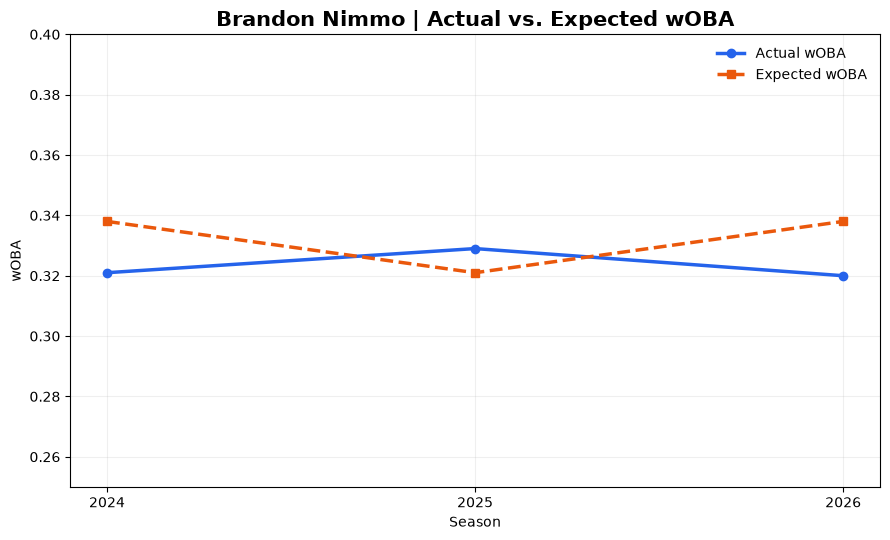

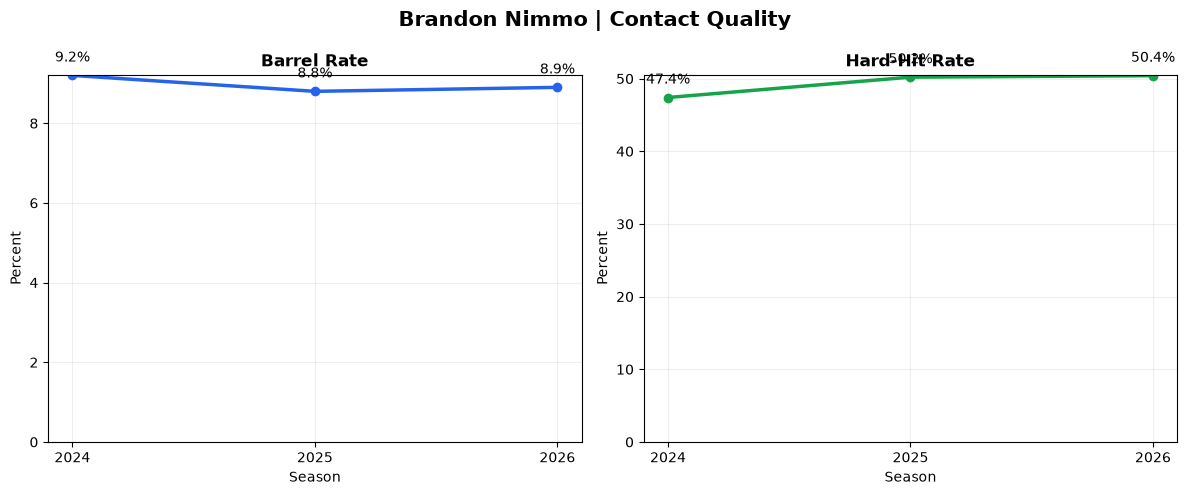

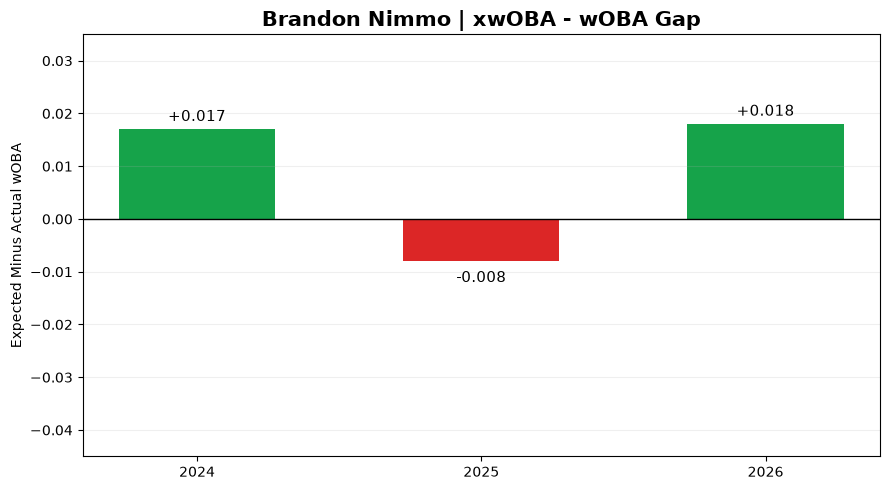

Saved three charts to: scouting_reports/brandon_nimmo


In [ ]:

create_scouting_visualizations(
    player_id=607043,
    player_name="Brandon Nimmo",
    folder_name="brandon_nimmo"
)


# Heliot Ramos | 2026 Offensive Scouting Report

**Evaluation:** 2024–2026 Statcast Performance  
**Category:** Contact-Quality Rebound  
**Priority:** High

### Executive Summary

Heliot Ramos presents one of the most compelling contact-quality rebound profiles in this analysis. Despite a decline in actual wOBA from .319 in 2025 to .312 in 2026, his expected wOBA improved from .320 to .329.

His barrel rate increased five percentage points, from 8.8% to 13.8%, while his hard-hit rate improved to 48.4%. This divergence between actual results and contact quality makes Ramos a particularly interesting player-development candidate.

### Historical Performance

| Metric | 2024 | 2025 | 2026 |
|---|---:|---:|---:|
| PA | 518 | 695 | 442 |
| wOBA | .339 | .319 | .312 |
| xwOBA | .338 | .320 | .329 |
| xwOBA Gap | -.001 | +.001 | +.017 |
| Barrel Rate | 14.7% | 8.8% | 13.8% |
| Hard-Hit Rate | 47.5% | 47.4% | 48.4% |

### Strengths

- Barrel rate improved by five percentage points from 2025.
- Expected wOBA improved despite declining actual production.
- Hard-hit rate increased to 48.4%.
- Barrel production approached his 2024 level.

### Areas of Concern

Ramos recorded fewer plate appearances in 2026 than in 2025, and his actual offensive production declined for a second consecutive season.

His increased strikeout rate, previously identified in the dataset, also warrants further evaluation. Improved contact quality is less valuable if reduced contact frequency offsets those gains.

### Baseball Operations Assessment

**Recommendation: High-Priority Development Evaluation**

Ramos presents a particularly strong case for deeper analysis of swing decisions, pitch recognition, strikeout trends, and batted-ball quality.

His improved barrel production suggests an offensive skill that may not have been fully reflected in his 2026 results.

### Final Recommendation

Prioritize Ramos for pitch-level analysis and offensive development review. Among the finalists, he presents some of the clearest evidence of meaningful improvement in underlying contact quality.

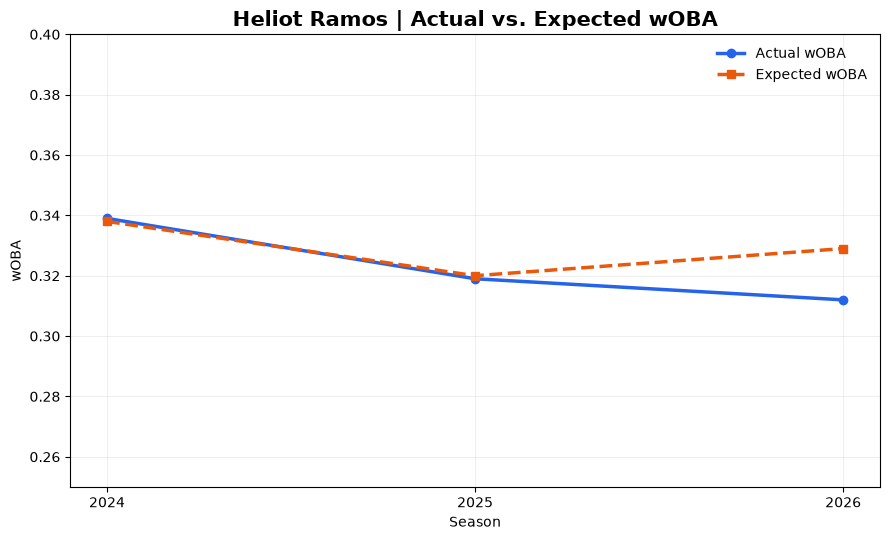

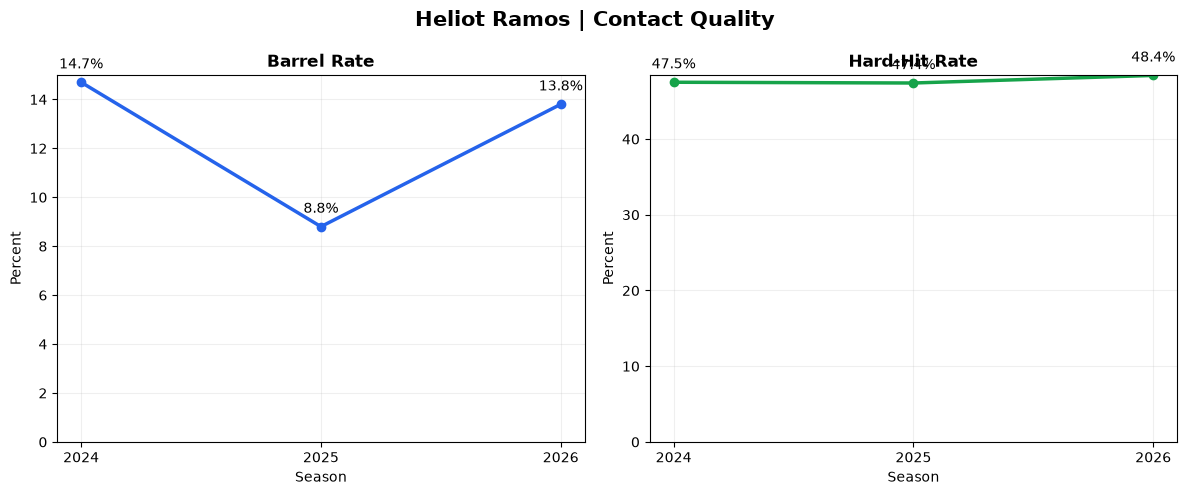

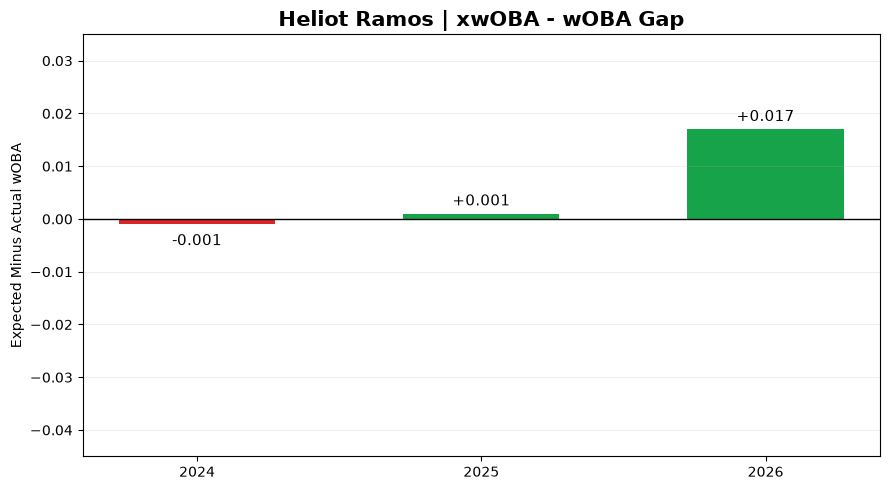

Saved three charts to: scouting_reports/heliot_ramos


In [ ]:

create_scouting_visualizations(
    player_id=671218,
    player_name="Heliot Ramos",
    folder_name="heliot_ramos"
)


# Masyn Winn | 2026 Offensive Scouting Report

**Evaluation:** 2024–2026 Statcast Performance  
**Category:** Moderate Expected-Performance Gap  
**Priority:** Medium

### Executive Summary

Masyn Winn finished 2026 with a .283 wOBA and .297 xwOBA, creating a positive expected-performance gap of .014.

While his expected production exceeded his actual results, his contact-quality profile presents a more limited rebound case than those of Nimmo and Ramos.

His barrel rate declined from 4.8% in 2025 to 3.3% in 2026, suggesting that additional offensive improvement may require changes beyond a favorable shift in batted-ball outcomes.

### Historical Performance

| Metric | 2024 | 2025 | 2026 |
|---|---:|---:|---:|
| PA | 637 | 537 | 532 |
| wOBA | .315 | .297 | .283 |
| xwOBA | .295 | .286 | .297 |
| xwOBA Gap | -.020 | -.011 | +.014 |
| Barrel Rate | 3.7% | 4.8% | 3.3% |
| Hard-Hit Rate | 32.7% | 34.6% | 34.9% |

### Strengths

- Expected wOBA improved from .286 in 2025 to .297 in 2026.
- Hard-hit rate increased modestly for a second consecutive season.
- Positive .014 expected-performance gap.
- Consistent playing-time sample across three seasons.

### Areas of Concern

Winn's actual wOBA declined each season, while his barrel rate remained relatively low.

The 2026 positive expected-performance gap alone is insufficient to establish a meaningful power breakout or significant offensive rebound.

### Baseball Operations Assessment

**Recommendation: Monitor**

Winn merits further analysis of his contact distribution, swing decisions, and offensive approach.

His profile may be more relevant to incremental offensive improvement than a substantial increase in power production.

### Final Recommendation

Maintain Winn as a secondary evaluation candidate. Additional evidence of improved contact quality or plate discipline would strengthen his offensive projection.

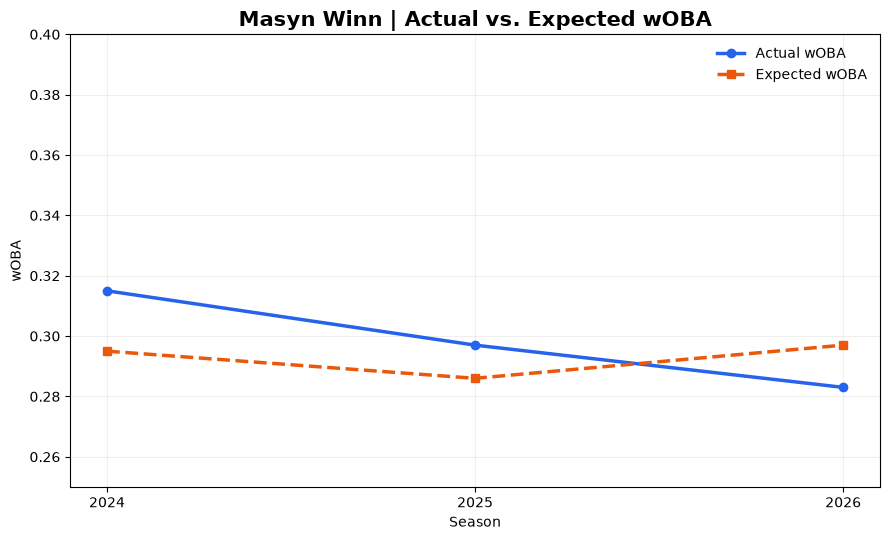

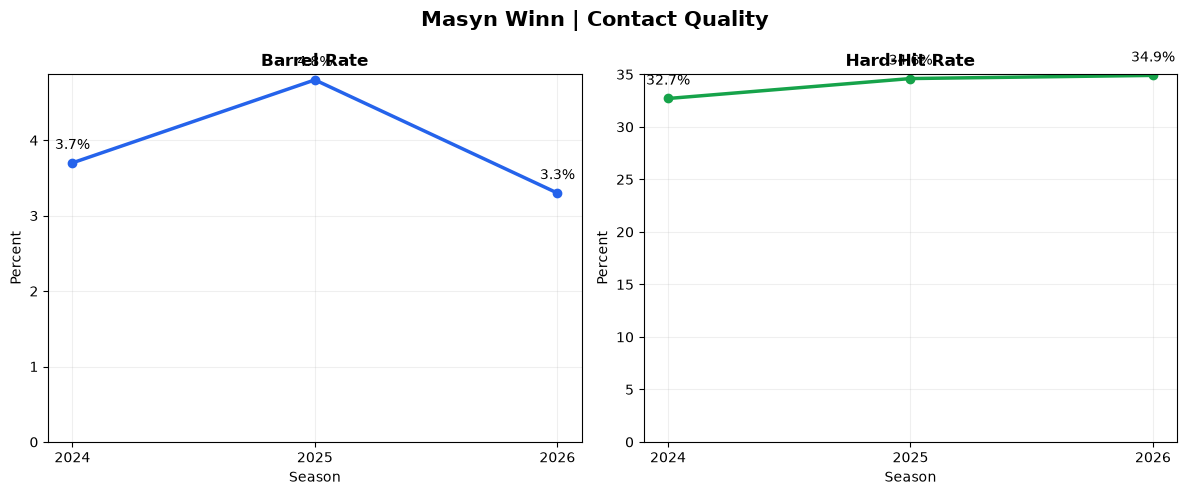

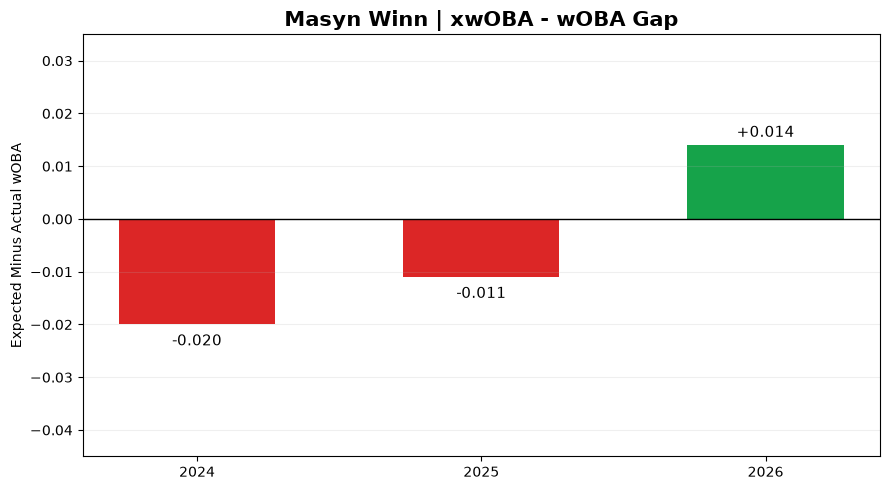

Saved three charts to: scouting_reports/masyn_winn


In [ ]:

create_scouting_visualizations(
    player_id=691026,
    player_name="Masyn Winn",
    folder_name="masyn_winn"
)


# Shea Langeliers | 2026 Offensive Scouting Report

**Evaluation:** 2024–2026 Statcast Performance  
**Category:** Strong Offensive Production  
**Priority:** Medium

### Executive Summary

Shea Langeliers recorded a .347 wOBA and .352 xwOBA in 2026, demonstrating strong offensive production and a relatively small positive expected-performance gap of .005.

Unlike several other finalists, Langeliers' appeal is less dependent on a potential statistical rebound and more closely related to his demonstrated ability to generate high-quality contact.

His barrel rate increased from 11.3% in 2025 to 13.3% in 2026, although his hard-hit rate declined slightly.

### Historical Performance

| Metric | 2024 | 2025 | 2026 |
|---|---:|---:|---:|
| PA | 534 | 522 | 467 |
| wOBA | .315 | .365 | .347 |
| xwOBA | .328 | .329 | .352 |
| xwOBA Gap | +.013 | -.036 | +.005 |
| Barrel Rate | 12.8% | 11.3% | 13.3% |
| Hard-Hit Rate | 44.0% | 44.9% | 43.0% |

### Strengths

- Highest 2026 xwOBA among the five finalists.
- Barrel rate increased two percentage points from 2025.
- Strong actual offensive production.
- Expected production improved substantially from 2025.

### Areas of Concern

The small expected-performance gap indicates that Langeliers' actual offensive results were already close to his expected production.

His hard-hit rate also declined by 1.9 percentage points, creating a mixed contact-quality picture.

### Baseball Operations Assessment

**Recommendation: Offensive Quality Follow-Up**

Langeliers deserves further evaluation based on his overall offensive profile, but he is not among the strongest rebound candidates under this project's methodology.

### Final Recommendation

Retain Langeliers as a high-quality offensive comparison player. Additional research should focus on the sustainability of his barrel production and his overall offensive value.

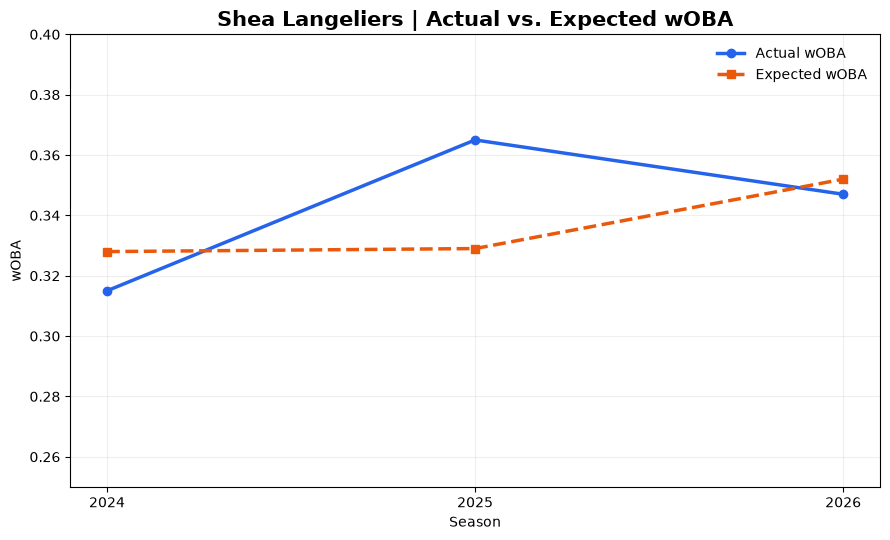

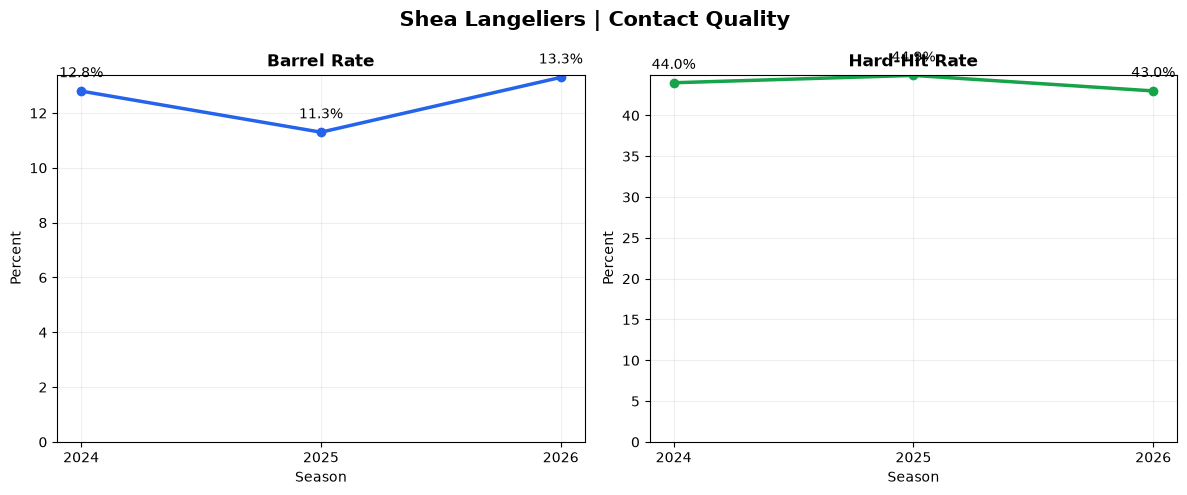

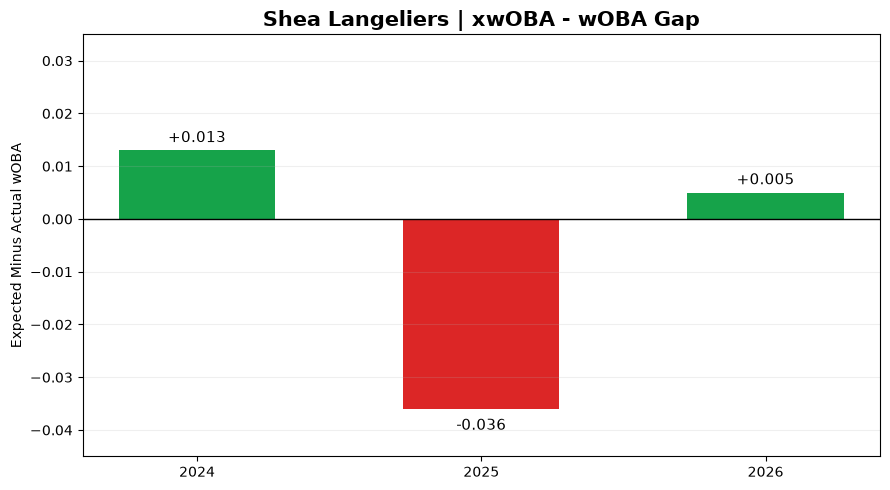

Saved three charts to: scouting_reports/shea_langeliers


In [ ]:

create_scouting_visualizations(
    player_id=669127,
    player_name="Shea Langeliers",
    folder_name="shea_langeliers"
)


# William Contreras | 2026 Offensive Scouting Report

**Evaluation:** 2024–2026 Statcast Performance  
**Category:** Established Offensive Production  
**Priority:** Low–Medium

### Executive Summary

William Contreras recorded a .330 wOBA and .334 xwOBA in 2026, producing a positive expected-performance gap of .004.

Although his barrel rate improved from 6.4% in 2025 to 8.5% in 2026, his hard-hit rate declined substantially over the same period.

Contreras remains a productive offensive player within this dataset, but his limited expected-performance gap provides less evidence of significant underperformance than the profiles of Nimmo or Ramos.

### Historical Performance

| Metric | 2024 | 2025 | 2026 |
|---|---:|---:|---:|
| PA | 679 | 659 | 640 |
| wOBA | .359 | .332 | .330 |
| xwOBA | .356 | .328 | .334 |
| xwOBA Gap | -.003 | -.004 | +.004 |
| Barrel Rate | 10.0% | 6.4% | 8.5% |
| Hard-Hit Rate | 49.5% | 48.5% | 44.1% |

### Strengths

- Consistent offensive production across substantial samples.
- Barrel rate improved by 2.1 percentage points from 2025.
- Expected wOBA increased slightly from 2025.
- More than 600 plate appearances in each season.

### Areas of Concern

Contreras' hard-hit rate declined by 4.4 percentage points from 2025 to 2026.

His actual wOBA also declined across the evaluation period, and the small positive expected-performance gap does not provide strong evidence of an imminent rebound.

### Baseball Operations Assessment

**Recommendation: Secondary Follow-Up**

Contreras warrants additional evaluation for his overall offensive ability and historical consistency, but his profile does not strongly satisfy the project's specific underperformance criteria.

### Final Recommendation

Use Contreras as a comparison case for established offensive production rather than a primary rebound target. Further work should investigate changes in contact quality and whether the decline in hard-hit rate reflects a sustainable trend.

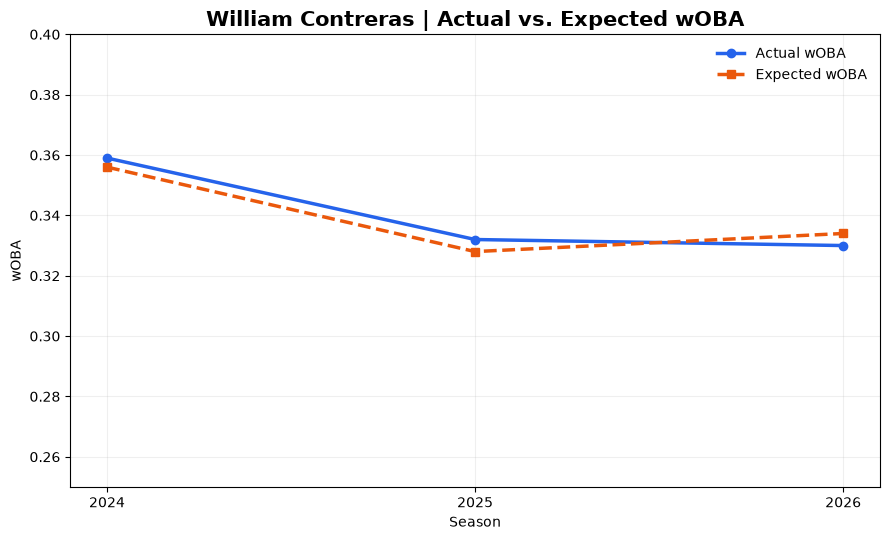

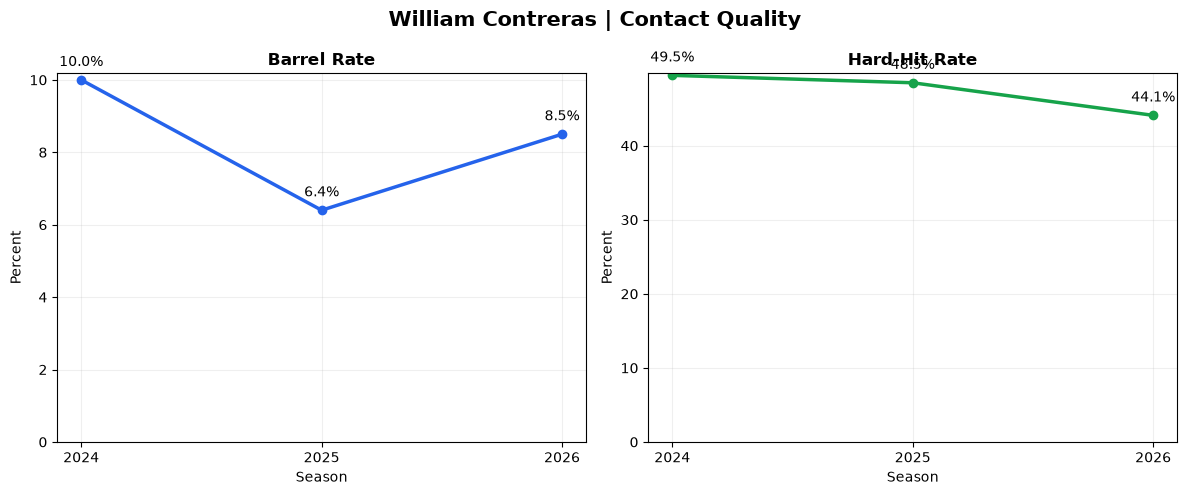

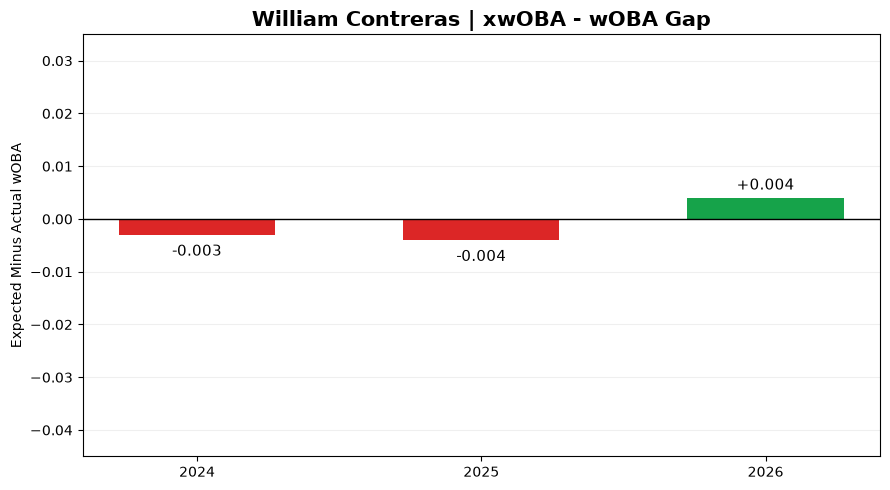

Saved three charts to: scouting_reports/william_contreras


In [ ]:

create_scouting_visualizations(
    player_id=661388,
    player_name="William Contreras",
    folder_name="william_contreras"
)


# Baseball Operations Research Memo
## Identifying Potentially Overlooked Offensive Value in MLB Hitters

**Department:** Baseball Operations / Research & Development  
**Evaluation Period:** 2024–2026  
**Analysis Type:** Offensive Performance and Player Identification  
**Tools:** Python, pandas, Matplotlib

---

## 1. Executive Objective

The objective of this analysis is to identify MLB hitters whose underlying offensive performance may be stronger than their observed statistical production suggests.

Traditional offensive statistics provide valuable information about a player's contributions but do not always distinguish between changes in underlying skill and differences in realized outcomes.

By combining expected offensive production, contact-quality metrics, and multiseason performance trends, this project develops an exploratory framework for identifying players who warrant additional scouting and analytical evaluation.

The analysis is designed to support three baseball operations functions:

- **Player Acquisition:** Identify hitters who may be overlooked when evaluating offensive production.
- **Player Development:** Identify players whose underlying contact quality suggests opportunities for offensive improvement.
- **Pro Scouting:** Prioritize players for further video analysis, statistical evaluation, and projection work.

The project is intended as an initial player-identification tool rather than a complete acquisition model.

## 2. Data and Evaluation Framework

### Data Sources

The analysis uses season-level MLB hitting data containing Statcast-derived metrics for the 2024, 2025, and 2026 seasons.

The primary variables include:

| Metric | Baseball Operations Application |
|---|---|
| wOBA | Measures realized offensive production |
| xwOBA | Estimates offensive performance from underlying outcomes |
| xwOBA − wOBA | Identifies differences between expected and realized production |
| Barrel Rate | Evaluates frequency of optimal batted-ball contact |
| Hard-Hit Rate | Measures frequency of batted balls hit at 95+ mph |
| Strikeout Rate | Evaluates contact and swing-and-miss tendencies |
| Walk Rate | Provides context for plate discipline |
| Plate Appearances | Provides sample-size context |

### Player Eligibility and Data Preparation

Player-season records were organized by MLB player ID and season to allow historical comparisons.

The analysis incorporated available records from three seasons, with 129 hitters in the 2024 dataset, 145 in 2025, and 267 in 2026.

Because the source datasets contain different numbers of hitters, the results should not be interpreted as a fully balanced MLB population. Any differences in source filters, qualification thresholds, or data completeness must be documented before publication.

The project also identified 122 players appearing in both the 2025 and 2026 datasets, allowing direct year-over-year comparisons.

### Primary Screening Metric

The initial screening metric was calculated as:

**Expected-Performance Gap = xwOBA − wOBA**

A positive value indicates that a player's expected offensive production exceeded actual production.

For example, a hitter with a .330 xwOBA and .310 wOBA would have an expected-performance gap of +.020.

This difference is a screening signal, not a direct estimate of future improvement.

## 3. Candidate Identification Process

The player-identification process consisted of four stages.

**Stage 1: Offensive Performance Screening**

Hitters were evaluated using actual wOBA, expected wOBA, and their differences. Players with positive expected-performance gaps were flagged for further review.

**Stage 2: Contact-Quality Evaluation**

Barrel rate and hard-hit rate were incorporated to distinguish players maintaining or improving their quality of contact from those whose underlying performance may be deteriorating.

**Stage 3: Historical Trend Analysis**

Performance from 2024 through 2026 was compared to evaluate whether observed changes represented sustained patterns, recent improvements, or isolated season-level fluctuations.

**Stage 4: Candidate Prioritization**

Exploratory composite scores were used to help rank candidates. These included expected-performance differences and contact-quality indicators.

The scores were manually designed analytical heuristics rather than statistically validated projections. Their weights and thresholds should be documented in the notebook, and the rankings should not be interpreted as predicted future wOBA.

Five hitters were ultimately selected for individual evaluation: Brandon Nimmo, Heliot Ramos, Masyn Winn, Shea Langeliers, and William Contreras.

## 4. Baseball Operations Findings

### Priority 1: Heliot Ramos — Contact-Quality Improvement

Ramos demonstrated a five-percentage-point increase in barrel rate between 2025 and 2026, accompanied by an improvement in xwOBA despite declining actual offensive production.

**Operational implication:** Prioritize video and pitch-level analysis to determine whether improved contact quality reflects a sustainable offensive adjustment.

### Priority 2: Brandon Nimmo — Expected-Performance Divergence

Nimmo recorded a +.018 expected-performance gap while maintaining a hard-hit rate above 50%.

**Operational implication:** Evaluate whether the difference between actual and expected results is likely to persist, and incorporate his offensive profile into a broader projection model.

### Priority 3: Masyn Winn — Limited Contact-Quality Improvement

Winn recorded a positive expected-performance gap, but his relatively low barrel rate limits evidence for a major power rebound.

**Operational implication:** Investigate batted-ball distribution, contact frequency, and plate discipline before assigning a stronger offensive projection.

### Secondary Evaluations: Shea Langeliers and William Contreras

Both players demonstrated established offensive production but relatively small positive expected-performance gaps.

**Operational implication:** Evaluate these players primarily on their overall offensive contributions and projected future value rather than treating them as leading statistical rebound candidates.

## 5. Limitations and Risk Assessment

### Expected Statistics Are Not Future Projections

xwOBA is an estimate of expected offensive outcomes, not a forecast of future production. A positive gap may reflect several factors and does not guarantee that actual wOBA will increase in the following season.

### Sample Selection

The three datasets contain different numbers of hitters. Differences in eligibility, playing time, and source filtering may introduce selection bias.

### Missing Context

The current framework does not fully incorporate:

- Pitch-type performance and swing decisions.
- Launch-angle and spray-direction distributions.
- Ballpark and environmental effects.
- Defensive positioning and baserunning.
- Injuries, aging, and changes in player approach.
- Salary, contract commitments, and acquisition cost.

### Model Validation

The composite scoring framework has not undergone out-of-sample testing.

Before using it for predictive decision-making, the model should be evaluated against subsequent-season performance using historical training and testing periods.

### Financial Valuation

The analysis identifies potential offensive underperformance rather than proving that a player is undervalued in the acquisition market.

A complete valuation would require projected WAR, contract obligations, acquisition cost, and other roster considerations.

## 6. Recommended Next Phase

The following analytical extensions would make this framework more useful for a professional baseball operations department.

**Pitch-Level Analysis**

Evaluate performance by pitch type, location, velocity, and count to identify potential swing-decision or contact-quality changes.

**Predictive Modeling**

Use historical player-season observations to test whether expected-performance gaps and contact-quality trends improve next-season offensive forecasts.

**Scouting Integration**

Compare statistical signals with professional scouting observations and video analysis to identify whether changes in offensive production reflect mechanical or approach adjustments.

**Acquisition Valuation**

Combine projected offensive contributions with defensive value, contractual commitments, and acquisition cost to evaluate potential roster value.

## 7. Final Baseball Operations Recommendation

This analysis identifies Heliot Ramos and Brandon Nimmo as the strongest candidates for additional offensive evaluation, although their profiles present different opportunities.

Ramos provides the clearer evidence of recent contact-quality improvement, while Nimmo demonstrates a larger gap between expected and realized offensive production.

The remaining finalists provide useful comparisons for evaluating the relationship between actual production, expected statistics, and underlying contact quality.

**The primary value of this framework is its ability to prioritize further evaluation, not to replace scouting judgment or establish definitive future projections.**

Integrating expected statistics, historical trends, and additional scouting information can help baseball operations departments allocate analytical resources and identify players whose offensive profiles deserve closer examination.

In [ ]:

# Baseball Operations — Methodology Verification

import pandas as pd

print("DATASET COVERAGE")
for year, data in [
    (2024, df_2024),
    (2025, df_2025),
    (2026, df_2026)
]:
    print(f"{year}: {data['player_id'].nunique()} unique players")

print("\nFINAL SCOUTING CANDIDATES")

finalist_ids = [607043, 671218, 691026, 669127, 661388]

finalists = final_profiles[
    final_profiles["player_id"].isin(finalist_ids)
].copy()

finalists["woba_gap"] = finalists["xwoba"] - finalists["woba"]

summary = finalists[finalists["year"] == 2026][
    [
        "last_name, first_name",
        "player_id",
        "pa",
        "woba",
        "xwoba",
        "woba_gap",
        "barrel_batted_rate",
        "hard_hit_percent"
    ]
].sort_values("woba_gap", ascending=False)

display(summary.round(3))


DATASET COVERAGE
2024: 129 unique players
2025: 145 unique players
2026: 267 unique players

FINAL SCOUTING CANDIDATES


,"last_name, first_name",player_id,pa,woba,xwoba,woba_gap,barrel_batted_rate,hard_hit_percent
375,"Nimmo, Brandon",607043,655,0.320,0.338,0.018,8.9,50.4
519,"Ramos, Heliot",671218,442,0.312,0.329,0.017,13.8,48.4
340,"Winn, Masyn",691026,532,0.283,0.297,0.014,3.3,34.9
397,"Langeliers, Shea",669127,467,0.347,0.352,0.005,13.3,43.0
277,"Contreras, William",661388,640,0.330,0.334,0.004,8.5,44.1
